# Atelier ML - Analyse d'image : Classification


## Détection vs Classification d’images
- **Detection**:  faite avec des algorithmes de traitement d'images
- **Classification**: faite avec l'IA pour reconnaitre une forme d'une autre avec des algorithmes entraines pour classifier les elements

## Classification: les reseaux de neurones convolutifs
L'algorithme d'apprentissage des reseaux de neurones convolutifs peut être assimilé à un millefeuille composé de plusieurs couches.  Les dernières couches (hautes du millefeuille) sont constituées de réseaux de neurones, dont les données en entrée sont issues des couches précédentes appelées couches de convolutions

### De nombreuses données d’apprentissage nécessaires
Pour que la machine puisse faire son apprentissage, elle va devoir manipuler l'image (traitement d'image)

### Un outil pour illustrer nos propos
Les réseaux de neurones convolutifs sont composés de plusieurs couches de traitements que l’on peut facilement schématiser. On peut visualiser l'intérieur du réseau de neurones convolutifs à l’aide d’un outil interactif disponible à cette adresse: [Adam Harley](https://adamharley.com/nn_vis/cnn/3d.html)

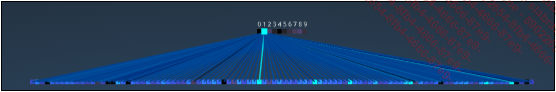

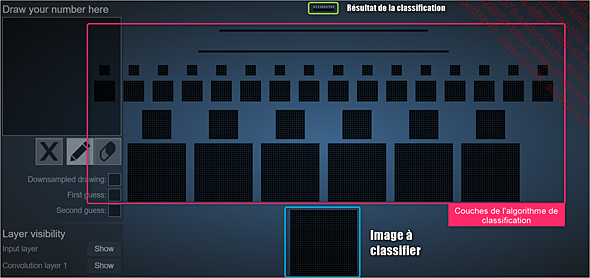

### L'image d’entrée
Les réseaux de neurones à convolution servent à classifier les images. Tout part donc d’une image source. La première chose que l’on observe est que notre image d’entrée (input layer) se trouve tout en bas de l’écran et se voit divisée en petits carrés. Ces carrés étant bien entendu les pixels de l’image. Si l’on remonte petit à petit, on voit également que d’autres images sont apparues jusqu’à obtenir la prédiction du chiffre dessiné (1 pour notre cas).

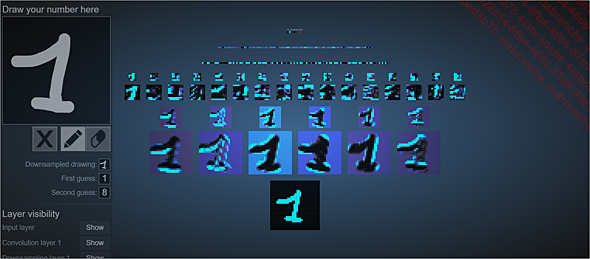

### Les caractéristiques
L'objectif de la notion de caractéristique est d'indiquer qu'une image de lapin par exemple est en fait un lapin ou non. L’une des solutions nous venant intuitivement à l’esprit pour résoudre ce problème est de comparer pixel par pixel deux images, une image d’apprentissage et une image à classifier.

Cependant, ceci comporte un incovénient, car l'image à classifier doit etre strictement identique à l'image de référence, ce qui est tout à fait impossible dans les cas réels d’application.

La solution sera donc de capturer des caractéristiques dans l’image source (des morceaux d’images) et à les rechercher dans l’image à classifier. C’est ce que l’on appelle le principe de convolution

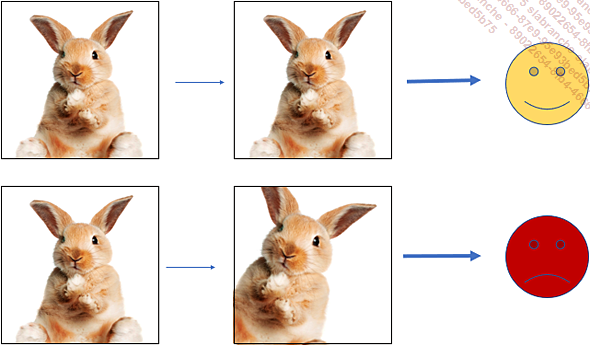

### La convolution

La phase d’apprentissage pour la convolution consiste à extraire ces caractéristiques pour ensuite alimenter un réseau de neurones afin qu’il apprenne à faire le lien entre les caractéristiques de l’image source couplées à une labellisation (nom de l’objet à reconnaître)

Voici un concept qui aide a visualiser ce qui se passe; considérons une image ayant une dimension de 5 pixels sur 5 pixels et une caractéristique de 3 pixels sur 3 pixels. Cette caractéristique est également appelée filtre ou kernel. Les pixels noirs de l’image porteront la valeur 1, les blancs 0 et les gris -1.

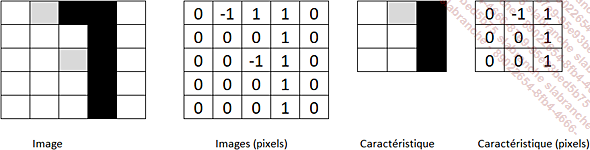

La convolution va consister à appliquer le filtre sur l’ensemble de l’image afin d’en déduire une nouvelle image. Les quatre figures suivantes expliquent le procédé :

- On place le filtre en haut et à gauche de l’image
- Pour chaque valeur de pixel de l’image se situant dans le filtre, on la multiplie par la valeur du pixel du filtre
- On réalise la somme de ces produits
- On se décale d’un pixel et on recommence le produit et la somme. Ce déplacement porte le nom de Stride et dans notre cas, a la valeur 1

Ce processus étant à réaliser jusqu’à ce que l’ensemble de l’image soit filtré, donnant ainsi naissance à une nouvelle image plus petite que l’image d’origine et ayant de nouvelles valeurs

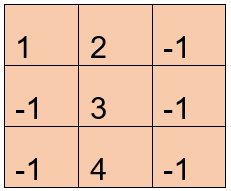

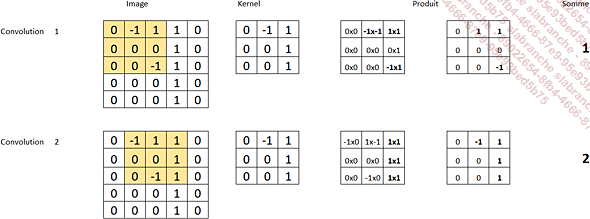

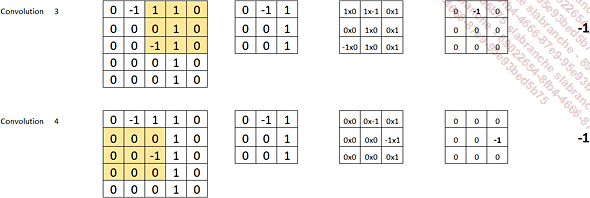

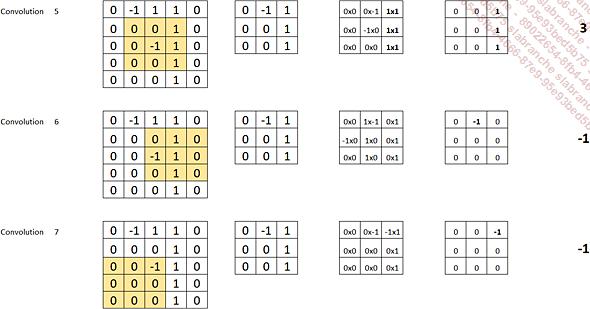

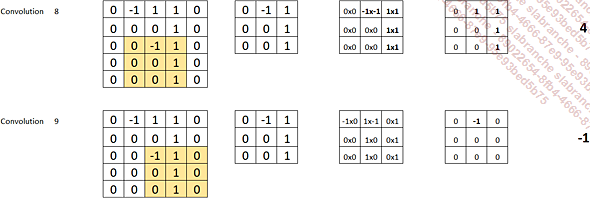

On peut observer qu’au-dessus de l’image d’entrée, il y a 6 autres images. Ces images sont issues de la convolution de 6 filtres. À droite, on trouve l’image issue du filtre n°1 et à gauche celle du filtre n°6. Les filtres appliqués sont d’une taille de 5 pixels * 5 pixels et sont bien entendu différents

Maintenant, si on applique ce traitement de convolution sur notre image de lapin, on peut se rendre compte que le nombre de calculs peut vite devenir important si la taille de l’image est grande et si l’on multiplie le nombre de filtres. Ce calcul demandant alors beaucoup de ressources au niveau de processeur et de la carte graphique

### Pooling
Le pooling consiste à déplacer une fenêtre dans l’image issue de la convolution. Dans le cadre d’un `MaxPooling`, on recherche la valeur maximale contenue à l’intérieur de cette fenêtre, dans le cadre d’un `Average Pooling`, on calcule la moyenne des valeurs contenues dans la fenêtre et enfin dans le cadre d’un `Pooling Stochastique`, on retient une valeur en fonction d’estimations probabilistiques

Reprenons l’image issue de notre convolution et appliquons-lui une fenêtre de pooling de 2 pixels sur 2 pixels avec un stride (déplacement) de 1 tout comme nous l’avons fait dans l’étape de convolution

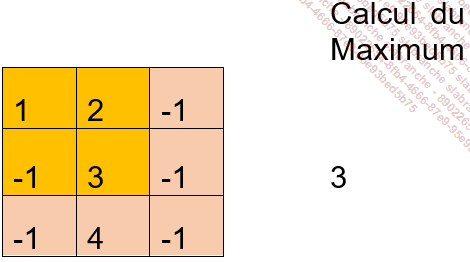

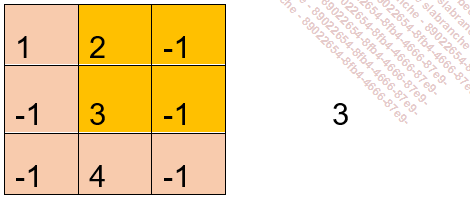

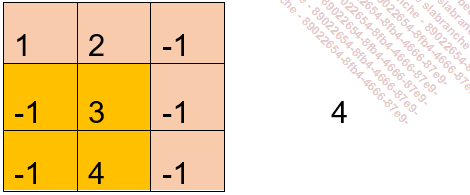

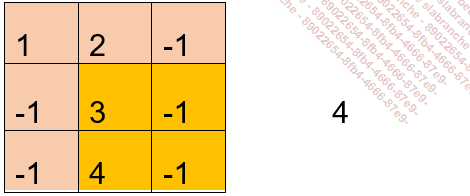

Resultat: 
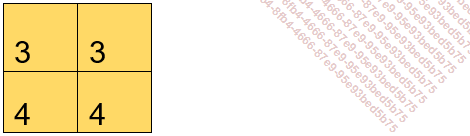

Il y a une reduction de taille de 5x5 a 2x2, tout en conservant les caractéristiques de l’image issue de la convolution

### Plusieurs couches de convolutions
Les couches de convolutions:
- Une première couche de convolution composée de 6 filtres de dimension 5x5 avec un stride de 1
- Une couche de pooling de taille 2x2
- Une seconde couche de convolution composée de 16 filtres de dimension 5x5 avec un stride de 1
- Une couche de pooling de taille 2x2
Objectif: réduire l’image tout en conservant les informations importantes
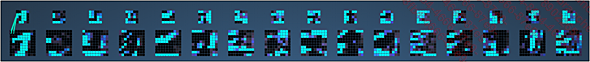

Les paramètres des différentes couches utilisées dans l’outil de visualisation sont disponibles dans le document PDF “An Interactive Node-Link Visualization of Convolutional Neural Networks” rédigé par Adam W. Harley et téléchargeable à cette adresse : http://scs.ryerson.ca/~aharley/vis/harley_vis_isvc15.pdf

### Mise à plat (Flatten)
Cette étape de préparation consiste à “mettre à plat” les différentes images issues des opérations de pooling sous forme d’une seule colonne (ou ligne dans l’outil). Nous créons alors un vecteur

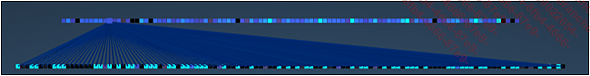

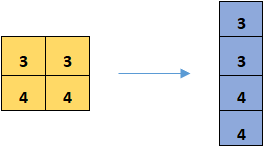

### L'apprentissage
Le fonctionnement de l’apprentissage est identique à celui que nous avons découvert dans le chapitre précédent : définition des poids, prédiction, rétropropagation…


## Un cas pratique autour de la mode

### Présentation de Kaggle
Kaggle (www.kaggle.com) est le site de référence en termes de propositions de défis liés au Machine Learning. Ce site regorge de cas d’études et de challenges proposés par de grands groupes tels que McDonalds, Netflix… Chacun d’entre nous peut tenter de résoudre ces différents défis en proposant ses propres modèles de prédiction. Ce site permet également d’apprendre énormément sur les techniques liées au Machine Learning, car chaque proposition de solution soumise par les participants aux différents défis est visible, commentée et peut ainsi être étudiée. Ce site est entièrement gratuit, alors pourquoi s’en priver ?

C’est à partir de ce site que nous allons réaliser notre cas pratique qui permettra d’illustrer les principes de codage d’un réseau de neurones à convolution

## Modules et configuration


In [21]:
import os

import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

# On force l'utilisation du processeur (CPU) plutôt que de la carte graphique
tf.config.set_visible_devices([], 'GPU')

# Définition de la longueur et de la largeur de l'image
LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

### De quelles données disposons-nous ?
Le fichier `fashion-mnist_train.csv` contient 60 000 images d'apprentissage. Chaque ligne est une image :
- la première colonne est le **label** (la catégorie du vêtement)
- les 784 autres colonnes sont les **pixels** (28 x 28), avec une valeur de luminosité entre 0 et 255

| Label | Catégorie |
|---|---|
| 0 | T-shirt/haut |
| 1 | Pantalon |
| 2 | Pull |
| 3 | Robe |
| 4 | Manteau |
| 5 | Sandales |
| 6 | Chemise |
| 7 | Baskets |
| 8 | Sac |
| 9 | Bottes de cheville |

In [35]:
#Chargement des images
observations_entrainement = pnd.read_csv('data/analyse_images/fashion-mnist_train.csv', dtype='uint8')

Pour vérifier que les images sont bien dans le fichier, on affiche la première. On exclut la première colonne (les labels) pour obtenir un tableau contenant uniquement les pixels, puis on le met en forme (`reshape`) en 28 x 28

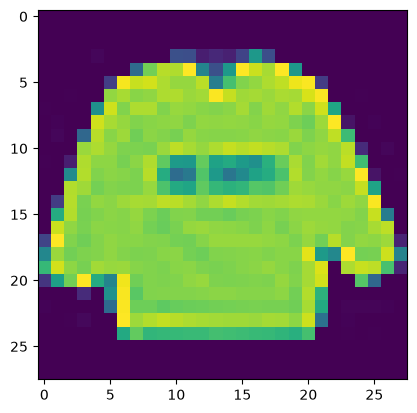

In [23]:
#On exclut la première colonne (les labels) pour constituer un tableau de pixels
X = np.array(observations_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE,LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

## Préparation des données d'apprentissage
Les réseaux de neurones ne travaillent qu'avec des valeurs numériques. On prépare donc les données ainsi :

1. Les labels sont transformés en **catégories binaires** avec `to_categorical`. Par exemple, le label 2 (Pull) devient `[0,0,1,0,0,0,0,0,0,0]`
2. On sépare les données : **80 %** pour l'apprentissage, **20 %** pour la validation
3. On redimensionne chaque image en 28 x 28 x 1 (une seule couche de couleur)
4. On fait une **mise à l'échelle** (scaling) : chaque pixel est divisé par 255 pour obtenir une valeur entre 0 et 1

In [24]:
# On crée des catégories à l'aide du module Keras
y = keras.utils.to_categorical(np.array(observations_entrainement.iloc[:, 0]), num_classes=10)

# Répartition des données d'entrainement en données d'apprentissage et données de validation
# 80% de données d'apprentissage et 20% de données de validation
X_apprentissage, X_validation, y_apprentissage, y_validation = train_test_split(X, y, test_size=0.2, random_state=13)

print("Apprentissage :", X_apprentissage.shape[0], "images")
print("Validation    :", X_validation.shape[0], "images")
print("Exemple de label (une catégorie binaire) :", y_apprentissage[0])

Apprentissage : 48000 images
Validation    : 12000 images
Exemple de label (une catégorie binaire) : [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [25]:
# On redimensionne les images au format 28*28 et on réalise un scaling sur les données des pixels
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0],
                                          LARGEUR_IMAGE,
                                          LONGUEUR_IMAGE, 1)
X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0],
                                    LARGEUR_IMAGE,
                                    LONGUEUR_IMAGE, 1)
X_validation = X_validation.astype('float32')
X_validation /= 255

print(X_apprentissage.shape, X_validation.shape)

(48000, 28, 28, 1) (12000, 28, 28, 1)


## Préparation des données de tests
Les données de tests servent à vérifier l'efficacité du modèle sur des images qu'il n'a jamais vues. Elles sont préparées de la même façon

In [ ]:
# Préparation des données de tests
observations_test = pnd.read_csv('data/analyse_images/fashion-mnist_test.csv', dtype='uint8')
X_test = np.array(observations_test.iloc[:, 1:])
y_test = tf.keras.utils.to_categorical(np.array(observations_test.iloc[:, 0]), num_classes=10)
X_test = X_test.reshape(X_test.shape[0],
                        LARGEUR_IMAGE,
                        LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

print(X_test.shape, y_test.shape)

(10000, 28, 28, 1) (10000, 10)


## Un réseau avec une seule couche de convolution

### Configuration
- une couche de convolution de **32 filtres** de taille 3x3 avec activation **ReLU**,
- un **pooling** 2x2,
- un **Dropout** (on ignore aléatoirement 20 % des neurones pendant l'apprentissage, pour éviter le surapprentissage)
- un **Flatten** (mise en colonne)
- une couche de **128 neurones** complètement connectée (ReLU)
- une couche de **10 neurones** (softmax) : une probabilité pour chacune des 10 catégories

In [27]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

# On spécifie les dimensions de l'image d'entrée
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

# On crée le réseau de neurones couche par couche
reseauNeurone1Convolution = Sequential()

# Ajout de la couche d'entrée
reseauNeurone1Convolution.add(Input(shape=dimentionImage))

# 1- Ajout de la couche de convolution comportant
# 32 filtres de taille 3x3 (Kernel) parcourant l'image
# Une fonction d'activation de type ReLU (Rectified Linear Activation)
reseauNeurone1Convolution.add(Conv2D(32,
                                     kernel_size=(3, 3),
                                     activation='relu'))

# 2- Définition de la fonction de pooling avec une fenêtre de 2px sur 2px
reseauNeurone1Convolution.add(MaxPooling2D(pool_size=(2, 2)))

# 3- Ajout d'une fonction d'ignorance (Dropout)
reseauNeurone1Convolution.add(Dropout(0.2))

# 4- On transforme en une seule ligne
reseauNeurone1Convolution.add(Flatten())

# 5- Ajout d'un réseau de neurones composé de 128 neurones avec
# une fonction d'activation de type ReLU
reseauNeurone1Convolution.add(Dense(128, activation='relu'))

# 6- Ajout d'un réseau de neurones composé de 10 neurones avec une
# fonction d'activation de type softmax
reseauNeurone1Convolution.add(Dense(10, activation='softmax'))

reseauNeurone1Convolution.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       692,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

### Compilation, apprentissage et test
La compilation précise :
- la fonction de minimisation de l'**erreur** (`categorical_crossentropy`)
- l'**optimiseur** Adam (méthode de descente de gradient)
- la valeur mesurée : la **précision** (`accuracy`)

Paramètres de l'apprentissage :
- `epochs=10` : 10 passages complets du jeu de données dans le réseau
- `batch_size=256` : 256 images traitées à la fois
- `verbose=1` : affichage des logs
- la validation utilise les 20 % de données de validation

Avec 48 000 images d'apprentissage et des paquets de 256 images, un epoch correspond à 48 000 / 256 ≈ 187 itérations

In [28]:
reseauNeurone1Convolution.compile(loss=keras.losses.categorical_crossentropy,
                                  optimizer=tf.keras.optimizers.Adam(),
                                  metrics=['accuracy'])

In [29]:
historique_apprentissage = reseauNeurone1Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.8112 - loss: 0.5498 - val_accuracy: 0.8708 - val_loss: 0.3836
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.8739 - loss: 0.3564 - val_accuracy: 0.8813 - val_loss: 0.3385
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8872 - loss: 0.3174 - val_accuracy: 0.8907 - val_loss: 0.3064
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8951 - loss: 0.2936 - val_accuracy: 0.8944 - val_loss: 0.3021
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9037 - loss: 0.2681 - val_accuracy: 0.8945 - val_loss: 0.2872
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9095 - loss: 0.2522 - val_accuracy: 0.9007 - val_loss: 0.2743
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9149 - loss: 0.2377 - val_accuracy: 0.9048 - val_loss: 0.2623
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9189 - loss: 0.2262 - val_accu

In [30]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Erreur: 0.23716367781162262
Précision: 0.9157000184059143


On affiche les courbes de précision et d'erreur après chaque epoch. La précision de l'apprentissage augmente et l'erreur diminue : c'est logique.

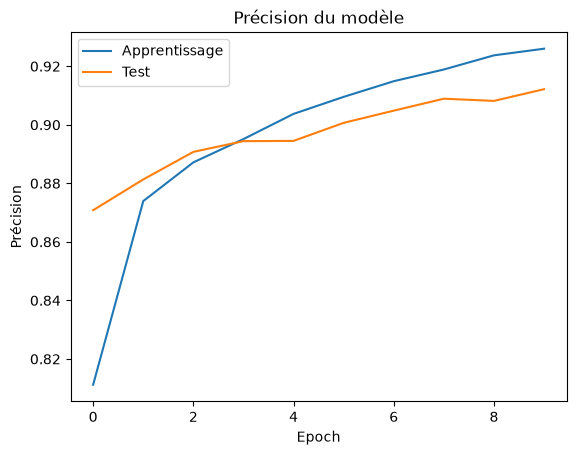

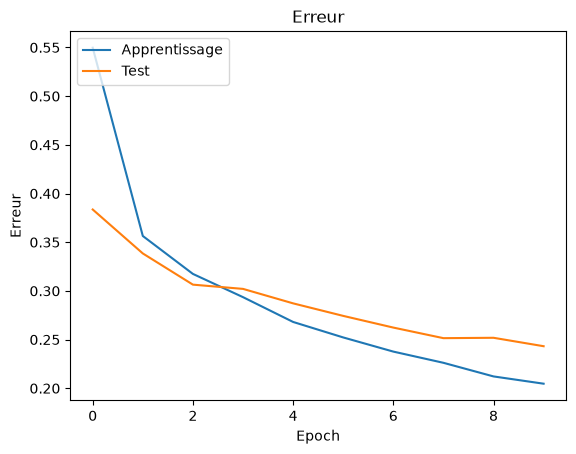

In [31]:
def afficher_courbes(historique):
    # Précision
    plt.plot(historique.history['accuracy'])
    plt.plot(historique.history['val_accuracy'])
    plt.title('Précision du modèle')
    plt.ylabel('Précision')
    plt.xlabel('Epoch')
    plt.legend(['Apprentissage', 'Test'], loc='upper left')
    plt.show()

    # Erreur
    plt.plot(historique.history['loss'])
    plt.plot(historique.history['val_loss'])
    plt.title('Erreur')
    plt.ylabel('Erreur')
    plt.xlabel('Epoch')
    plt.legend(['Apprentissage', 'Test'], loc='upper left')
    plt.show()


afficher_courbes(historique_apprentissage)

### Conclusion sur l'apprentissage
La précision sur le jeu de tests est d'environ 90 % (les valeurs peuvent varier d'une exécution à l'autre). Un jeu de tests peut contenir des images que le jeu d'apprentissage ne contient pas : pour améliorer le résultat, on peut **augmenter le nombre d'images d'apprentissage**.

## Augmentation du nombre de données
Inutile de chercher d'autres photos : la fonction `ImageDataGenerator` de Keras crée de nouvelles images à partir de celles du jeu d'apprentissage, en leur appliquant au hasard :
- une **rotation** (`rotation_range`),
- des **translations** horizontale et verticale (`width_shift_range`, `height_shift_range`),
- un **cisaillement** (`shear_range`),
- un **zoom** (`zoom_range`).

On passe de 10 à **50 epochs**, car on dispose de plus d'images. Comme le générateur produit des images sans fin, il faut indiquer le nombre d'itérations par epoch (`steps_per_epoch`) : 48 000 / 256 = 187 pour l'apprentissage, 12 000 / 256 = 46 pour la validation.

> Cet entraînement est plus long (environ 10 minutes) : les nouvelles images sont générées pendant l'apprentissage. Le modèle `reseauNeurone1Convolution` poursuit son apprentissage à partir de ce qu'il a déjà appris.

In [32]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

generateur_images = tf.keras.preprocessing.image.ImageDataGenerator(
    rotation_range=8,
    width_shift_range=0.08,
    shear_range=0.3,
    height_shift_range=0.08,
    zoom_range=0.08)

nouvelles_images_apprentissage = generateur_images.flow(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256)

nouvelles_images_validation = generateur_images.flow(
    X_validation, 
    y_validation,
    batch_size=256)

historique_apprentissage = reseauNeurone1Convolution.fit(
    nouvelles_images_apprentissage,
    steps_per_epoch=48000//256,
    epochs=50,
    validation_data=nouvelles_images_validation,
    validation_steps=12000//256,
    verbose=1 )

evaluation = reseauNeurone1Convolution.evaluate(X_test, y_test, verbose=0)

print('Erreur :', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/50


I0000 00:00:1793754213.862832    3364 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 51ms/step - accuracy: 0.8241 - loss: 0.4716 - val_accuracy: 0.8423 - val_loss: 0.4234
Epoch 2/50
  1/187 ━━━━━━━━━━━━━━━━━━━━ 7s 42ms/step - accuracy: 0.8164 - loss: 0.4403

/home/marwan/420-5G4-ML/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.8164 - loss: 0.4403 - val_accuracy: 0.8416 - val_loss: 0.4246
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.8476 - loss: 0.4148 - val_accuracy: 0.8560 - val_loss: 0.3808
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8281 - loss: 0.4315 - val_accuracy: 0.8550 - val_loss: 0.3903
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8545 - loss: 0.3933 - val_accuracy: 0.8503 - val_loss: 0.3937
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8438 - loss: 0.3732 - val_accuracy: 0.8589 - val_loss: 0.3788
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.8610 - loss: 0.3739 - val_accuracy: 0.8601 - val_loss: 0.3761
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8711 - loss: 0.3870 - val_accuracy: 0.8628 - val_loss: 0.3670
Epoch 9/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - accuracy: 0.8634 - loss: 0.3667 - val_accuracy: 0.86

## Sauvegarde du modèle
Le modèle est sauvegardé dans le répertoire `modele` en deux fichiers :
- `modele.json` : la **définition** du modèle,
- `modele.weights.h5` : les **poids** issus de l'apprentissage.

Ils seront utilisés par `test_model.ipynb`.

In [38]:
# Sauvegarde du modèle
# Sérialisation du modèle
model_json = reseauNeurone1Convolution.to_json()
with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)

# Sérialisation des poids
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modèle sauvegardé !")

Modèle sauvegardé !


## Un modèle plus performant - Optionel

In [40]:
from keras.layers import BatchNormalization

reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

/home/marwan/420-5G4-ML/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [41]:
reseauNeurones4Convolution.compile(loss=keras.losses.categorical_crossentropy, 
                                  optimizer=tf.keras.optimizers.Adam(), 
                                  metrics=['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(
    X_apprentissage, 
    y_apprentissage,
    batch_size=256,
    epochs=10,
    verbose=1,
    validation_data=(X_validation, y_validation))

evaluation = reseauNeurones4Convolution.evaluate(X_test, y_test, verbose=0)
print('Erreur:', evaluation[0])
print('Précision:', evaluation[1])

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 47s 238ms/step - accuracy: 0.7431 - loss: 0.7352 - val_accuracy: 0.1871 - val_loss: 3.2048
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 229ms/step - accuracy: 0.8449 - loss: 0.4366 - val_accuracy: 0.4927 - val_loss: 2.0720
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 44s 234ms/step - accuracy: 0.8697 - loss: 0.3624 - val_accuracy: 0.7681 - val_loss: 0.6712
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 87s 262ms/step - accuracy: 0.8847 - loss: 0.3248 - val_accuracy: 0.8961 - val_loss: 0.2837
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 45s 237ms/step - accuracy: 0.8931 - loss: 0.3017 - val_accuracy: 0.8967 - val_loss: 0.2829
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 229ms/step - accuracy: 0.9012 - loss: 0.2805 - val_accuracy: 0.9050 - val_loss: 0.2602
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 235ms/step - accuracy: 0.9060 - loss: 0.2648 - val_accuracy: 0.9119 - val_loss: 0.2483
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 43s 227ms/step - accuracy: 0.9091 - loss: 0